In [1]:
import os
import pandas as pd

data_path = os.path.join("..", "data", "raw", "RW_LFS2024.dta")
df = pd.read_stata(data_path)

print("Rows:", len(df))
print("Columns:", len(df.columns))

Rows: 102562
Columns: 197


In [2]:
print("Class counts:")
print(df["status1"].value_counts(dropna=False))
print("\nClass percentages:")
print(df["status1"].value_counts(normalize=True, dropna=False) * 100)

Class counts:
status1
NaN                    36259
Employed               33594
out of labour force    26857
Unemployed              5852
Name: count, dtype: int64

Class percentages:
status1
NaN                    35.353250
Employed               32.754821
out of labour force    26.186112
Unemployed              5.705817
Name: proportion, dtype: float64


In [3]:
df_clean = df.dropna(subset=["status1"]).copy()

feature_cols = [
    "A01",
    "A04",
    "A05",
    "Code_UR",
    "code_dis",
    "attained",
    "hhsize",
    "status1"
]

df_subset = df_clean[feature_cols].copy()

print("Working-age sample size:", len(df_subset))
print("\nFirst 5 rows:")
print(df_subset.head())

Working-age sample size: 66303

First 5 rows:
      A01 A04                   A05 Code_UR    code_dis         attained  \
0    Male  45  Married monogamously   Urban  Nyarugenge          Primary   
1  Female  44  Married monogamously   Urban  Nyarugenge          Primary   
2  Female  19                Single   Urban  Nyarugenge  Lower secondary   
3    Male  19                Single   Urban  Nyarugenge  Lower secondary   
4  Female  15                Single   Urban  Nyarugenge          Primary   

       hhsize              status1  
0   9 persons             Employed  
1   9 persons             Employed  
2   9 persons             Employed  
3   9 persons  out of labour force  
4   9 persons  out of labour force  


In [4]:
rename_map = {
    "A01": "gender",
    "A04": "age",
    "A05": "marital_status",
    "Code_UR": "urban_rural",
    "code_dis": "district",
    "attained": "education_level",
    "hhsize": "household_size",
    "status1": "labor_status"
}

df_clean = df_subset.rename(columns=rename_map)

print(df_clean.info())
print("\nMissing values per column:")
print(df_clean.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 66303 entries, 0 to 102559
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   gender           66303 non-null  category
 1   age              66303 non-null  category
 2   marital_status   66303 non-null  category
 3   urban_rural      66303 non-null  category
 4   district         66303 non-null  category
 5   education_level  66303 non-null  category
 6   household_size   66303 non-null  category
 7   labor_status     66303 non-null  category
dtypes: category(8)
memory usage: 1.0 MB
None

Missing values per column:
gender             0
age                0
marital_status     0
urban_rural        0
district           0
education_level    0
household_size     0
labor_status       0
dtype: int64


C:\Users\user1\AppData\Local\Temp\ipykernel_22564\3410828585.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="labor_status", palette="viridis")


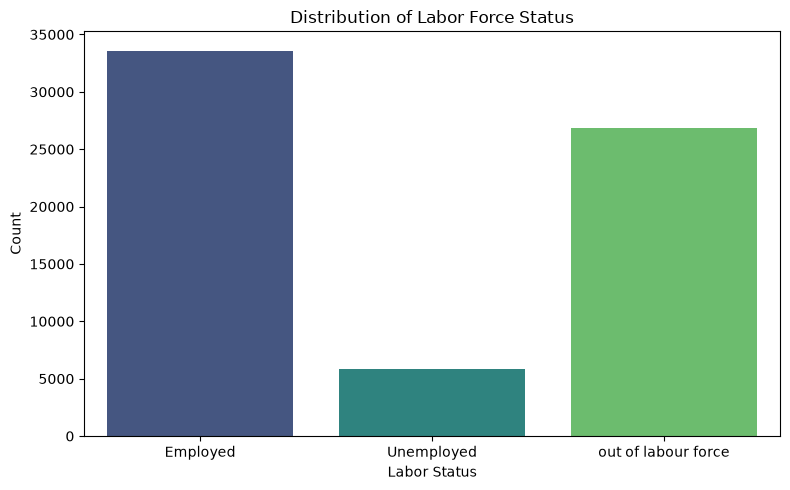

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

df_clean.to_csv("../data/processed/lfs_cleaned.csv", index=False)

plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="labor_status", palette="viridis")
plt.title("Distribution of Labor Force Status")
plt.xlabel("Labor Status")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("../figures/eda/target_distribution.png", dpi=300)
plt.show()